# Pratinjau Denah Lantai 6
Notebook ini memuat data ruangan + konfigurasi Lt. 6, memvalidasi geometri (overlap, dinding bersama, keterjangkauan) lalu menggambar denahnya. Jalankan semua sel (`Run All`) dan bandingkan dengan foto denah asli.

Kebutuhan: `pip install geopandas shapely matplotlib pandas`

In [1]:

%pip install geopandas shapely matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


In [11]:
import io, os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from shapely.geometry import box, Point
from shapely.ops import unary_union

# --- Data ruangan (identik dengan csv/lantai6.csv) ---
CSV_TEXT = """floor,room_id,name,type,xmin,ymin,xmax,ymax
6,06003,Tangga Barat Lt 6,Stairs,0.00,50.20,3.00,60.00
6,619002,Station 1 (619B),Lab,3.00,55.80,8.20,60.00
6,618004,Station 2 (618D),Lab,8.20,55.80,13.40,60.00
6,618003,Station 3 (618C),Lab,13.40,55.80,18.70,60.00
6,617004,Station 4 (617D),Lab,18.70,55.80,23.80,60.00
6,617003,Station 5 (617C),Lab,23.80,55.80,29.10,60.00
6,616003,Station 6 (616C),Lab,29.10,55.80,34.30,60.00
6,616002,Station 7 (616B),Lab,34.30,55.80,39.70,60.00
6,619001,Ruang Kendali (619A),Lab,5.40,49.20,9.70,53.50
6,618002,Station 12 (618B),Lab,9.70,49.20,14.90,53.50
6,618001,Station 11 (618A),Lab,14.90,49.20,20.00,53.50
6,617002,Station 10 (617B),Lab,20.00,49.20,25.30,53.50
6,617001,Station 9 (617A),Lab,25.30,49.20,30.50,53.50
6,616001,Station 8 (616A),Lab,30.50,49.20,35.80,53.50
6,620,Lab Bio Oral (620),Lab,-1.50,39.60,10.10,47.00
6,621,Kelas 621,Classroom,10.10,39.60,20.00,47.00
6,622,Kelas 622,Classroom,20.00,39.60,30.00,47.00
6,623,Kelas 623,Classroom,30.00,39.60,39.70,47.00
6,006001,Toilet Wanita Lt 6,Toilet,39.70,55.10,46.20,60.00
6,006002,Toilet Pria Lt 6,Toilet,39.70,52.20,46.20,55.10
6,006004,Toilet Disable Lt 3,Toilet,39.70,50.00,42.40,52.20
6,006003,Toilet VIP Lt 6,Toilet,42.40,50.00,46.20,52.20
6,06001,Lift Barat Lt 6,Lift,46.20,53.20,49.20,57.70
6,06002,Lift Timur Lt 6,Lift,54.30,50.00,58.00,57.70
6,06004,Tangga Utara Lt 6,Stairs,58.00,50.00,60.30,57.70
6,0006001,Pantry Lt 6,Pantry,57.50,57.70,60.30,60.00
6,608,Lab IMTKG (608),Lab,60.30,50.00,69.90,60.00
6,609,Kelas FKG (609),Classroom,69.90,50.00,78.90,60.00
6,610,Collaboration & Global Engagement (610),Office,78.90,50.00,88.90,60.00
6,611,Teaching & Learning Innovation Center (611),Office,88.90,50.00,96.10,60.00
6,06005,Tangga Timur Lt 6,Stairs,96.10,50.00,99.45,60.00
6,615002,Ruang Wakil Dekan FKG 1 (615B),LecturerRoom,60.30,42.40,63.00,47.00
6,615003,Ruang Wakil Dekan FKG 2 (615C),LecturerRoom,63.00,42.40,65.60,47.00
6,615004,Ruang Wakil Dekan FKG 3 (615D),LecturerRoom,65.60,42.40,68.20,47.00
6,614,Ruang Dosen FKG (614),LecturerRoom,68.20,39.60,78.90,47.00
6,613,Kelas 613,Classroom,78.90,39.60,89.30,47.00
6,612,Ruang UKM (612),Storage,89.30,39.60,99.45,47.00
6,625,Kelas 625,Classroom,39.70,39.60,43.90,46.40
6,626001,Storage (626A),Storage,43.90,43.70,50.50,46.40
6,626002,Ruang DEU (626B),Office,43.90,39.60,50.50,43.70
6,627,Kelas 627,Classroom,39.70,37.60,50.50,39.60
6,607,LPPM (607),Office,39.70,21.70,50.50,37.60
6,606,Kelas FKG (606),Classroom,39.70,12.20,50.50,21.70
6,605,Skill Lab (605),Lab,39.70,2.60,50.50,12.20
6,601,Academic Support FKG (601),Office,54.30,40.90,57.30,47.00
6,615001,Ruang Dekan FKG (615A),LecturerRoom,57.30,42.40,60.30,47.00
6,601001,Ruang Meeting (601A),MeetingRoom,54.30,37.90,57.30,40.90
6,615005,Ruang Dekan FKG (615E),LecturerRoom,57.30,37.90,60.30,40.90
6,602001,Ruang Monitor (602A),Lab,54.30,36.20,58.30,37.90
6,602002,Gudang (602B),Storage,58.30,36.20,60.30,37.90
6,602,Lab Psychology (602),Lab,54.30,26.00,60.30,36.20
6,603,Lab Psychology (603),Lab,54.30,13.70,60.30,26.00
6,604,Kelas FKG (604),Classroom,54.30,5.50,60.30,13.70
6,06006,Tangga Selatan Lt 6,Stairs,54.30,2.60,60.30,5.50
"""
rooms = pd.read_csv(io.StringIO(CSV_TEXT), dtype={"floor": str, "room_id": str})

# --- Konfigurasi (identik dengan floors/lantai6.py) ---
OUTLINE = [
    (-1.5, 39.6, 39.7, 47.0),
    (0.0, 47.0, 99.45, 60.0),
    (39.7, 2.6, 60.3, 47.0),
    (60.3, 39.6, 99.45, 47.0),
    (38.2, 2.6, 39.7, 39.6),
    (60.3, 4.5, 62.0, 39.6),
]
VOIDS = [
    (38.2, 2.6, 39.7, 39.6),
    (60.3, 4.5, 62.0, 39.6),
]
START = (51.8, 48.5)
PART_OF = {

}

rooms["geometry"] = [box(r.xmin, r.ymin, r.xmax, r.ymax) for r in rooms.itertuples()]
gdf = gpd.GeoDataFrame(rooms, geometry="geometry")
print(f"{len(gdf)} ruangan dimuat")
gdf[["room_id", "name", "type", "xmin", "ymin", "xmax", "ymax"]]


54 ruangan dimuat


,room_id,name,type,xmin,ymin,xmax,ymax
0,06003,Tangga Barat Lt 6,Stairs,0.0,50.2,3.00,60.0
1,619002,Station 1 (619B),Lab,3.0,55.8,8.20,60.0
2,618004,Station 2 (618D),Lab,8.2,55.8,13.40,60.0
3,618003,Station 3 (618C),Lab,13.4,55.8,18.70,60.0
4,617004,Station 4 (617D),Lab,18.7,55.8,23.80,60.0
5,617003,Station 5 (617C),Lab,23.8,55.8,29.10,60.0
6,616003,Station 6 (616C),Lab,29.1,55.8,34.30,60.0
7,616002,Station 7 (616B),Lab,34.3,55.8,39.70,60.0
8,619001,Ruang Kendali (619A),Lab,5.4,49.2,9.70,53.5
9,618002,Station 12 (618B),Lab,9.7,49.2,14.90,53.5


## Validasi geometri & walkable area

In [12]:
# ===== Validasi geometri =====
overlaps, shared = [], 0
for i in range(len(gdf)):
    for j in range(i + 1, len(gdf)):
        a, b = gdf.iloc[i], gdf.iloc[j]
        inter = a.geometry.intersection(b.geometry)
        if inter.area > 1e-6:
            overlaps.append((a.room_id, b.room_id, round(inter.area, 3)))
        elif inter.length > 1e-6:
            shared += 1
print("Overlap antar ruangan :", overlaps or "tidak ada")
print("Pasangan ruangan dengan dinding bersama:", shared)

outline = unary_union([box(*b) for b in OUTLINE])
voids = unary_union([box(*b) for b in VOIDS])
outside = [r.room_id for r in gdf.itertuples() if not outline.buffer(1e-6).contains(r.geometry)]
print("Ruangan di luar OUTLINE:", outside or "tidak ada")

# ===== Walkable area (OUTLINE - ruangan - VOIDS) =====
walkable = outline.difference(unary_union(list(gdf.geometry))).difference(voids)
parts = list(walkable.geoms) if walkable.geom_type == "MultiPolygon" else [walkable]
main = next(p for p in parts if p.buffer(1e-6).contains(Point(START)))
print(f"Walkable total {walkable.area:.1f} m2 | komponen dari START {main.area:.1f} m2 | jumlah komponen {len(parts)}")

unreach = [f"{r.room_id} {r.name}" for r in gdf.itertuples() if not r.geometry.buffer(0.05).intersects(main)]
print("Ruangan yang TIDAK menyentuh area walkable:", unreach or "tidak ada")
for k, p in PART_OF.items():
    print(f"PART_OF {k} walkable?", main.buffer(1e-6).contains(Point(p)))


Overlap antar ruangan : tidak ada
Pasangan ruangan dengan dinding bersama: 58
Ruangan di luar OUTLINE: tidak ada
Walkable total 657.8 m2 | komponen dari START 631.2 m2 | jumlah komponen 2
Ruangan yang TIDAK menyentuh area walkable: ['615005 Ruang Dekan FKG (615E)', '602002 Gudang (602B)']


## Gambar denah

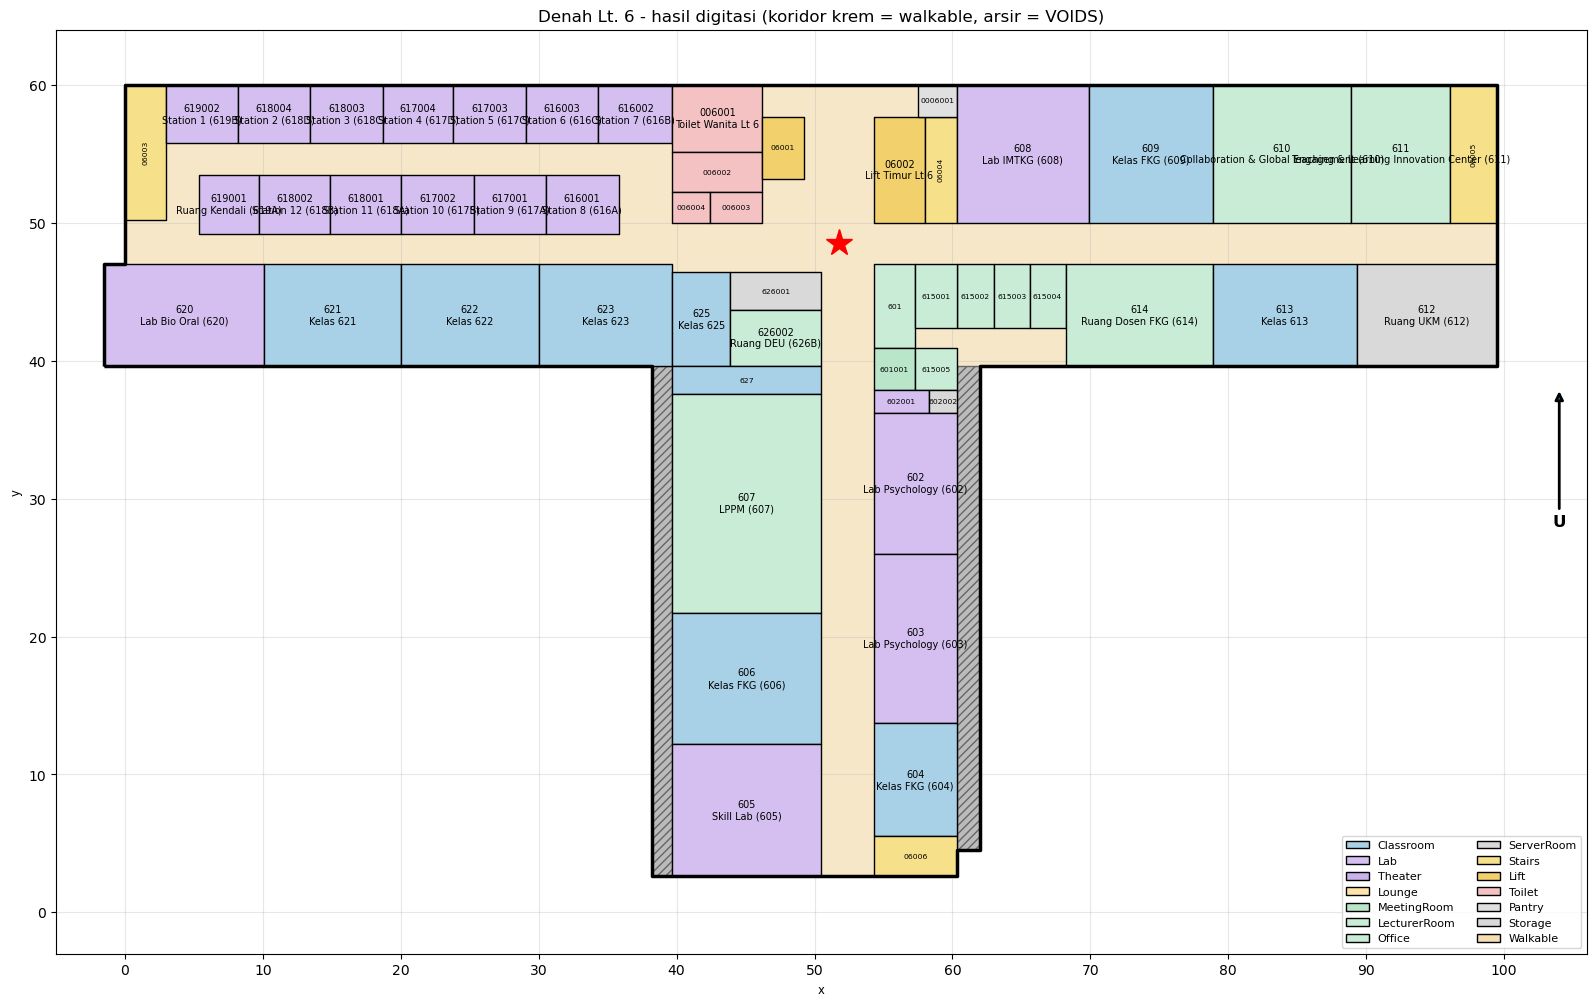

In [13]:
COLORS = {
    "Classroom": "#a8d0e6", "Lab": "#d4bff0", "Theater": "#c9b3e8", "Lounge": "#ffe3a8",
    "MeetingRoom": "#b9e6c9", "LecturerRoom": "#c8ecd5", "Office": "#c8ecd5",
    "ServerRoom": "#d9d9d9", "Stairs": "#f7e08a", "Lift": "#f2d06b",
    "Toilet": "#f4c2c2", "Pantry": "#e0e0e0", "Storage": "#d9d9d9",
}
fig, ax = plt.subplots(figsize=(20, 12))
gpd.GeoSeries([walkable]).plot(ax=ax, color="#f5deb3", alpha=0.7, zorder=1)
gpd.GeoSeries([voids]).plot(ax=ax, facecolor="#bbbbbb", edgecolor="#666666", hatch="////", zorder=2)
gdf.plot(ax=ax, color=gdf["type"].map(COLORS), edgecolor="black", linewidth=1.0, zorder=3)
gpd.GeoSeries([outline]).boundary.plot(ax=ax, color="black", linewidth=2.5, zorder=4)

for r in gdf.itertuples():
    cx, cy = r.geometry.centroid.x, r.geometry.centroid.y
    w, h = r.xmax - r.xmin, r.ymax - r.ymin
    small = min(w, h) < 3.6
    label = r.room_id if small else f"{r.room_id}\n{r.name}"
    ax.text(cx, cy, label, ha="center", va="center", fontsize=5.5 if small else 7,
            rotation=90 if h > 2.5 * w else 0, zorder=6)

ax.plot(*START, marker="*", color="red", markersize=20, zorder=7, label="START")
for k, p in PART_OF.items():
    ax.plot(*p, marker="D", color="blue", markersize=9, zorder=7)
    ax.annotate(f"PART_OF {k}", p, xytext=(4, 6), textcoords="offset points", fontsize=7, color="blue")

ax.annotate("U", xy=(104, 38), xytext=(104, 28), ha="center", fontsize=12, fontweight="bold",
            arrowprops=dict(arrowstyle="-|>", lw=2))
ax.set_xlim(-5, 106); ax.set_ylim(-3, 64)
ax.set_aspect("equal"); ax.grid(True, alpha=0.3)
ax.set_xticks(range(0, 101, 10)); ax.set_yticks(range(0, 61, 10))
ax.set_title("Denah Lt. 6 - hasil digitasi (koridor krem = walkable, arsir = VOIDS)")
legend = [Patch(facecolor=c, edgecolor="black", label=t) for t, c in COLORS.items()]
legend.append(Patch(facecolor="#f5deb3", edgecolor="black", label="Walkable"))
ax.legend(handles=legend, loc="lower right", fontsize=8, ncol=2)
fig.savefig("lantai6_preview.png", dpi=130, bbox_inches="tight")
plt.show()


In [14]:
rooms.to_csv("csv/lantai6.csv", index=False)

In [15]:
rooms.drop(columns=['geometry']).to_csv("csv/lantai6.csv", index=False)

## Overlay ke foto denah asli (opsional)

In [ ]:
# Opsional: tempel kerangka hasil digitasi di atas foto denah asli untuk cek kesesuaian.
# Simpan foto denah Lt. 6 sebagai "denah_lt6.jpg" di folder yang sama dengan notebook ini.
IMAGE_PATH = "denah_lt6.jpg"
if os.path.exists(IMAGE_PATH):
    import matplotlib.image as mpimg
    img = mpimg.imread(IMAGE_PATH)
    # asumsi foto 1600x1279 px; skala 15.07 px/m, origin x=66px, y=210px (y=60 m)
    extent = [-66 / 15.07, (1600 - 66) / 15.07, 60 - (1279 - 210) / 15.07, 60 + 210 / 15.07]
    fig, ax = plt.subplots(figsize=(20, 12))
    ax.imshow(img, extent=extent, zorder=0)
    gdf.boundary.plot(ax=ax, color="red", linewidth=1.3, zorder=3)
    for r in gdf.itertuples():
        ax.text(r.geometry.centroid.x, r.geometry.centroid.y, r.room_id, color="red",
                fontsize=6, ha="center", va="center", zorder=4)
    ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
    ax.set_title("Overlay: garis merah = hasil digitasi, latar = foto denah asli")
    plt.show()
else:
    print(f"{IMAGE_PATH} tidak ditemukan - lewati overlay (opsional).")
